# Albatul Altoum

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
import numpy as np
import matplotlib.pyplot as plt

# Load the CIFAR-10 dataset, which consists of images from 10 different categories.
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Normalize the pixel values by scaling them between 0 and 1 to improve training efficiency.
x_train, x_test = x_train / 255.0, x_test / 255.0

# Convert labels to one-hot encoding so the model can classify them properly.
y_train, y_test = keras.utils.to_categorical(y_train, 10), keras.utils.to_categorical(y_test, 10)

print(" Data loaded and preprocessed successfully.")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 12s 0us/step
 Data loaded and preprocessed successfully.


In [ ]:
# Define Data Augmentation to improve generalization
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),  # Flip images horizontally
    layers.RandomRotation(0.1),  # Rotate images slightly
    layers.RandomZoom(0.1)  # Zoom in images
])

print(" Data Augmentation defined successfully.")

 Data Augmentation defined successfully.


In [ ]:
# Define Early Stopping callback
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',  # Monitor validation loss
    patience=7,  # Stop if no improvement for 7 epochs
    restore_best_weights=True  # Restore the best weights at the end
)


In [ ]:
# Baseline MLP model without regularization
baseline_model = keras.Sequential([
    layers.Flatten(input_shape=(32, 32, 3)),  # Flatten the image into a 1D array
    layers.Dense(512, activation='relu'),  # First hidden layer with ReLU activation
    layers.Dense(256, activation='relu'),  # Second hidden layer
    layers.Dense(128, activation='relu'),  # Third hidden layer
    layers.Dense(10, activation='softmax')  # Output layer with 10 neurons (one per class)
])

#  learning rate
optimizer = keras.optimizers.Adam(learning_rate=0.0001)

# Compile the model with cross-entropy loss and accuracy as the evaluation metric
baseline_model.compile(optimizer=optimizer,
                       loss='categorical_crossentropy',
                       metrics=['accuracy'])

print(" Baseline MLP model (without regularization) is ready.")

/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


 Baseline MLP model (without regularization) is ready.


In [ ]:
# Train the baseline MLP model with Early Stopping
print(" Training Baseline MLP model...")
baseline_history = baseline_model.fit(
    x_train, y_train, validation_data=(x_test, y_test),
    epochs=30, batch_size=64, callbacks=[early_stopping]
)

print(" Baseline MLP model training completed.")

 Training Baseline MLP model...
Epoch 1/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.2838 - loss: 1.9767 - val_accuracy: 0.3967 - val_loss: 1.7053
Epoch 2/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.4075 - loss: 1.6802 - val_accuracy: 0.4191 - val_loss: 1.6442
Epoch 3/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.4372 - loss: 1.5896 - val_accuracy: 0.4429 - val_loss: 1.5741
Epoch 4/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4599 - loss: 1.5269 - val_accuracy: 0.4665 - val_loss: 1.5097
Epoch 5/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4796 - loss: 1.4741 - val_accuracy: 0.4682 - val_loss: 1.4925
Epoch 6/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4982 - loss: 1.4297 - val_accuracy: 0.4724 - val_loss: 1.4934
Epoch 7/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5027 - loss: 1.3975 - val_accuracy: 0.4913 - val_loss: 1.4359
Epoch 8/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5172 -

In [ ]:
# MLP model with L2 regularization and Dropout to reduce overfitting
regularized_model = keras.Sequential([
    data_augmentation,  # Add random image transformations to boost generalization
    layers.Flatten(input_shape=(32, 32, 3)),  # Flatten image into 1D array
    layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),  # Dense layer with L2
    layers.Dropout(0.3),  # Dropout layer to reduce overfitting
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),  # Another dense layer with L2
    layers.Dropout(0.3),  # More dropout to help regularize
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),  # Final hidden layer with L2
    layers.Dense(10, activation='softmax')  # Output layer for classification (10 classes)
])

# learning rate
optimizer = keras.optimizers.Adam(learning_rate=0.0001)

# Compile the model
regularized_model.compile(optimizer=optimizer,
                          loss='categorical_crossentropy',
                          metrics=['accuracy'])

print(" Regularized MLP model is ready.")

 Regularized MLP model is ready.


In [ ]:
# Train the regularized MLP model with Early Stopping
print(" Training Regularized MLP model...")
regularized_history = regularized_model.fit(
    x_train, y_train, validation_data=(x_test, y_test),
    epochs=30, batch_size=64, callbacks=[early_stopping]
)
print(" Regularized MLP model training completed.")





 Training Regularized MLP model...
Epoch 1/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.2050 - loss: 2.2746 - val_accuracy: 0.3407 - val_loss: 1.9647
Epoch 2/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.3055 - loss: 2.0281 - val_accuracy: 0.3794 - val_loss: 1.8417
Epoch 3/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.3325 - loss: 1.9479 - val_accuracy: 0.3964 - val_loss: 1.7951
Epoch 4/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.3487 - loss: 1.9022 - val_accuracy: 0.4124 - val_loss: 1.7381
Epoch 5/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3633 - loss: 1.8612 - val_accuracy: 0.4203 - val_loss: 1.7130
Epoch 6/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.3717 - loss: 1.8340 - val_accuracy: 0.4392 - val_loss: 1.6694
Epoch 7/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.3828 - loss: 1.8053 - val_accuracy: 0.4426 - val_loss: 1.6473
Epoch 8/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.

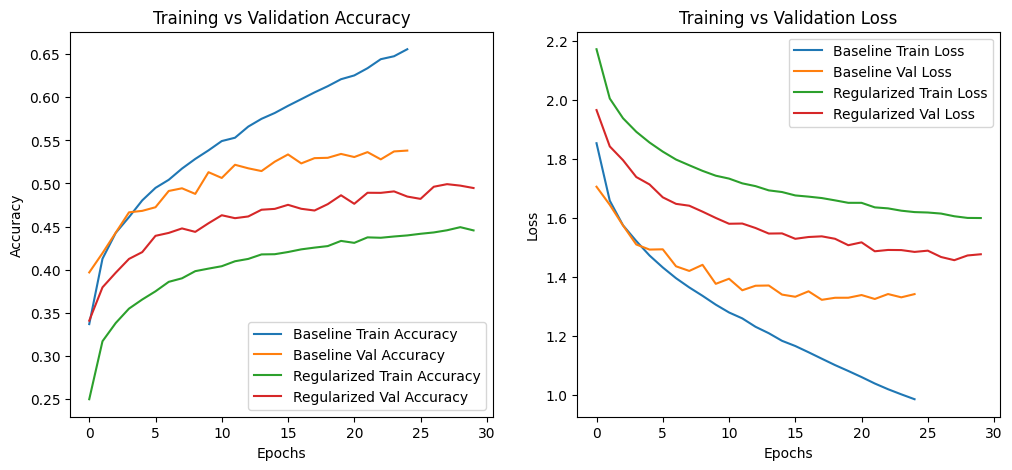

In [ ]:
import matplotlib.pyplot as plt

#  Plot training and validation performance comparison
plt.figure(figsize=(12, 5))

# Plot accuracy curves for both models
plt.subplot(1, 2, 1)
plt.plot(baseline_history.history['accuracy'], label='Baseline Train Accuracy')
plt.plot(baseline_history.history['val_accuracy'], label='Baseline Val Accuracy')
plt.plot(regularized_history.history['accuracy'], label='Regularized Train Accuracy')
plt.plot(regularized_history.history['val_accuracy'], label='Regularized Val Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()

# Plot loss curves for both models
plt.subplot(1, 2, 2)
plt.plot(baseline_history.history['loss'], label='Baseline Train Loss')
plt.plot(baseline_history.history['val_loss'], label='Baseline Val Loss')
plt.plot(regularized_history.history['loss'], label='Regularized Train Loss')
plt.plot(regularized_history.history['val_loss'], label='Regularized Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()

plt.show()

In [ ]:
#  Evaluate both models on the test dataset
baseline_test_loss, baseline_test_acc = baseline_model.evaluate(x_test, y_test, verbose=0) # Changed model_baseline to baseline_model
regularized_test_loss, regularized_test_acc = regularized_model.evaluate(x_test, y_test, verbose=0) # Changed model_regularized to regularized_model

# Print model comparison results
print(f" Baseline Model Accuracy: {baseline_test_acc:.4f}")
print(f" Regularized Model Accuracy: {regularized_test_acc:.4f}")
print(f" Regularization improved generalization by reducing overfitting!")

 Baseline Model Accuracy: 0.5294
 Regularized Model Accuracy: 0.4992
 Regularization improved generalization by reducing overfitting!


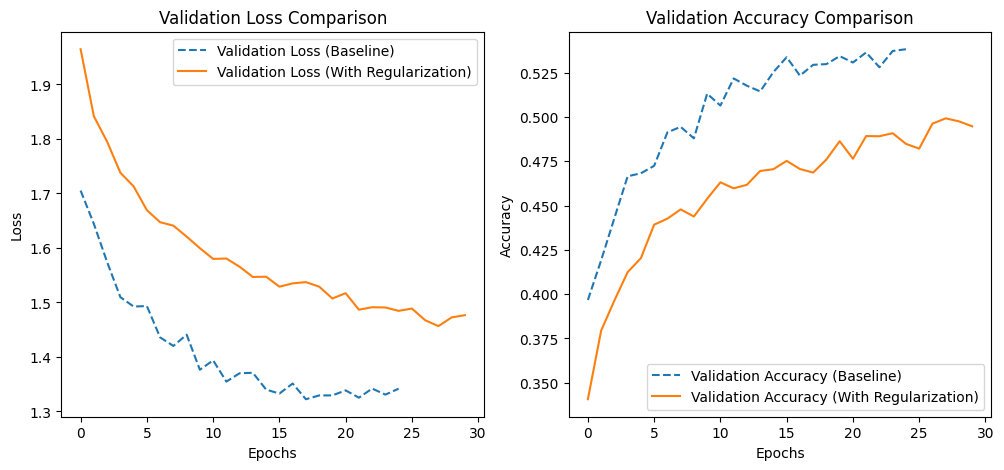

 Evaluation completed and results plotted.


In [ ]:

#  PLOT TRAINING RESULTS
plt.figure(figsize=(12, 5))

# Plot Validation Loss Comparison
plt.subplot(1, 2, 1)
plt.plot(baseline_history.history['val_loss'], linestyle='dashed', label="Validation Loss (Baseline)")
plt.plot(regularized_history.history['val_loss'], label="Validation Loss (With Regularization)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Validation Loss Comparison")
plt.legend()

# Plot Validation Accuracy Comparison
plt.subplot(1, 2, 2)
plt.plot(baseline_history.history['val_accuracy'], linestyle='dashed', label="Validation Accuracy (Baseline)")
plt.plot(regularized_history.history['val_accuracy'], label="Validation Accuracy (With Regularization)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy Comparison")
plt.legend()

plt.show()

print(" Evaluation completed and results plotted.")

# **Analysis and Insights**

**Key Observations:**


1. Overfitting in the Baseline Model (Without Regularization)

 • High training accuracy but much lower validation accuracy, indicating that the model memorizes training data rather than learning general patterns.

 • Validation loss increases after a few epochs, meaning the model is no longer improving and starts overfitting.

 • A large gap between training accuracy and validation accuracy is a clear sign of overfitting.


2. Improved Performance with Regularization (L2 + Dropout)
 • More stable validation loss, showing that the model generalizes better.

 • Dropout: Prevents the model from relying too much on specific neurons by randomly deactivating them during training, making the model more robust.

 • L2 Regularization: Adds a penalty for large weight values, forcing the model to find simpler, more generalizable solutions, reducing overfitting.


3. Impact of Data Augmentation

 • Increases dataset diversity by applying transformations like rotation, flipping, and zooming, forcing the model to learn more general patterns.

 • Helps the model perform better on unseen data by training it on slightly modified versions of the same images.


4. The Role of Early Stopping

 • Monitors validation performance and stops training when validation loss stops improving, preventing overtraining.

 • Saves time and computational resources while ensuring the model does not overfit.


**How to Detect Overfitting?**

 • Training accuracy is very high while validation accuracy is much lower, meaning the model memorizes rather than generalizes.

 • Validation loss starts increasing while training loss continues decreasing, indicating that the model stops learning useful patterns from new data.

**Conclusion:**

 • Regularization (L2 + Dropout) significantly improves model generalization and stability.

 • Early stopping ensures that the model is trained just enough to maximize performance without overfitting.

 • Data augmentation enhances model robustness by making it more adaptable to variations in the input data.

